In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
import seaborn as sns
import csv

# Set the path to the folder with the throughput results
basepath = "./tp_res_1/"

# Read Throughput from CSV files and return a list
def readThroughput(pathname):
    throughputs = {}
    times = [1, 10, 100, 1000]

    # Go trough all the coherence times
    for i in times:
        throughputs[i] = []

        # Go through the number of experiments
        for j in range (100):
            fname = f"{basepath}throughput_results_{i}_{j+1}.csv"
            try:
                with open(fname, newline='') as csvfile:
                    spamreader = csv.reader(csvfile, delimiter=' ', quotechar='|')
                    # Skip the header line, Strings make for terrible numbers
                    header = next(spamreader, None)

                    # Put the data from the csv into the dictionary at the coherence time
                    for row in spamreader:
                        t_var = ', '.join(row).split(",")[1]
                        throughputs[i].append(float(t_var))
            except FileNotFoundError:
                # print("File ", fname, " not found")
                continue
    # Return all the throughput values at one
    return [throughputs[1], throughputs[10], throughputs[100],throughputs[1000]]

throughput = readThroughput(basepath)

box_plot = sns.boxplot(data=throughput, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(t) for t in throughput]

vertical_offset = [m * 0.01 for m in medians]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + vertical_offset[xtick],
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='black',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Mbps")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 180)

plt.title("Throughput Boxplot, TCP Cubic, 20MHz channel, high mobility")
#plt.title("Throughput Boxplot, TCP Cubic, 80MHz channel, low mobility, outdoor munich")
#plt.savefig("throughput_boxplot.png")

# TODO: Example for issue for mitsuba in python
# TODO: Raytracer config, remove diffractions
# TODO: Remove AP from SnR
# TODO: Random Number stream for mobility helper, AssignStream or something.
# TODO: Remove outliers, all throughput values with 0mbps should not be shown.
# TODO: Get Position from MobilityHelper


In [ ]:
"""
Throughput and SNR plotting script for ns-3 Sionna simulations.

This script parses throughput and SNR CSV files produced by the simulation
pipeline and generates publication-quality boxplots and time-series plots.
It is highly modular, allowing comparison across different paths,
seeds, and coherence times.
"""

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Iterable

class SimulationPlotter:
    def __init__(
        self,
        results_base: str,
        coherence_times: List[int],
        seeds: Iterable[int],
        save_plots: bool = False,
        output_dir: str = "."
    ):
        """
        Initialize the plotter with the simulation configuration.

        :param results_base: Base directory containing the 'tc{coherence}' folders.
        :param coherence_times: List of coherence times (in ms) to analyze.
        :param seeds: Iterable of seeds to process (e.g., range(1, 11)).
        :param save_plots: Whether to save the generated plots to disk.
        :param output_dir: Where to save the plots if save_plots is True.
        """
        self.results_base = results_base
        self.coherence_times = coherence_times
        self.seeds = list(seeds)
        self.save_plots = save_plots
        self.output_dir = output_dir

        self.measuring_intervals = [10, 100]

        if self.save_plots and not os.path.exists(self.output_dir):
            os.makedirs(self.output_dir)

    # ── Path Helpers ─────────────────────────────────────────────────────────

    def tp_path(self, tc: int, seed: int) -> str:
        return os.path.join(
            self.results_base,
            f"tc{tc}",
            f"throughput_results_{tc}_{seed}.csv",
        )

    def snr_path(self, tc: int, seed: int) -> str:
        return os.path.join(
            self.results_base,
            f"tc{tc}",
            f"snr_results_{tc}_{seed}.csv",
        )

    # ── Data Parsers ─────────────────────────────────────────────────────────

    def read_throughput_file(self, tc: int, seed: int) -> dict:
        """Parse a single throughput CSV file, excluding zero-throughput samples."""
        path = self.tp_path(tc, seed)
        result = {iv: [] for iv in self.measuring_intervals}
        try:
            with open(path, newline="") as fh:
                reader = csv.reader(fh)
                header = next(reader, None)
                if header is None:
                    return result
                for row in reader:
                    if len(row) < 3:
                        continue
                    try:
                        t = float(row[0].strip())
                        tp = float(row[1].strip())
                        iv = int(float(row[2].strip()))
                        if tp == 0.0:          # ← skip zero-throughput samples
                            continue
                        if iv in result:
                            result[iv].append((t, tp))
                    except (ValueError, IndexError):
                        continue
        except FileNotFoundError:
            pass
        return result

    def read_snr_file(self, tc: int, seed: int) -> list:
        """
        Parse a single SNR CSV file (v1: 8-column format).
        Returns a list of (time, snr_db) tuples for STA_NodeId == 0 only.
        """
        path = self.snr_path(tc, seed)
        data = []
        try:
            with open(path, newline="") as fh:
                reader = csv.reader(fh)
                header = next(reader, None)
                if header is None:
                    return data
                for row in reader:
                    # Time_s, STA_NodeId, pos_x, pos_y, pos_z, PathLoss_dB, RxPower_dBm, SNR_dB
                    if len(row) < 8:
                        continue
                    try:
                        t = float(row[0].strip())
                        node_id = int(float(row[1].strip()))
                        snr = float(row[7].strip())
                        if node_id != 1:       # ← skip the AP (node 1)
                            continue
                        data.append((t, snr))
                    except (ValueError, IndexError):
                        continue
        except FileNotFoundError:
            pass
        return data

    def collect_throughput_values(self, interval_ms: int) -> dict:
        """Collect throughput samples across all coherence times and seeds."""
        data = {tc:[] for tc in self.coherence_times}
        for tc in self.coherence_times:
            for seed in self.seeds:
                parsed = self.read_throughput_file(tc, seed)
                for (_t, tp) in parsed.get(interval_ms, []):
                    data[tc].append(tp)
        return data

    def collect_snr_values(self) -> dict:
        """Collect SNR samples across all coherence times and seeds."""
        data = {tc:[] for tc in self.coherence_times}
        for tc in self.coherence_times:
            for seed in self.seeds:
                parsed = self.read_snr_file(tc, seed)
                for (_t, snr) in parsed:
                    data[tc].append(snr)
        return data

    # ── Plotting Routines ────────────────────────────────────────────────────

    def plot_throughput_boxplot(self, interval_ms: int, title: str):
        data = self.collect_throughput_values(interval_ms)
        values = [data[tc] for tc in self.coherence_times]
        labels =[f"{tc/10} ms" for tc in self.coherence_times]

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = sns.boxplot(data=values, ax=ax, widths=0.5)

        medians =[np.median(v) if v else float("nan") for v in values]
        for xtick in bp.get_xticks():
            m = medians[xtick]
            if not np.isnan(m):
                bp.text(
                    xtick, m + abs(m) * 0.01, f"{m:.2f}",
                    horizontalalignment="center", size="x-small",
                    color="black", weight="semibold"
                )

        ax.set_xticks(range(len(self.coherence_times)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("Coherence Time")
        ax.set_ylabel("Throughput (Mbps)")
        ax.set_title(title)
        ax.set_ylim(bottom=0)
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.2)
        plt.show()

    def plot_throughput_over_time(self, seed: int, title: str):
        fig, axes = plt.subplots(
            len(self.measuring_intervals), 1,
            figsize=(14, 5 * len(self.measuring_intervals)),
            sharex=True,
        )
        if len(self.measuring_intervals) == 1:
            axes = [axes]

        for ax, iv in zip(axes, self.measuring_intervals):
            for tc in self.coherence_times:
                parsed = self.read_throughput_file(tc, seed)
                pts = parsed.get(iv,[])
                if not pts:
                    continue
                times = [p[0] for p in pts]
                tps =[p[1] for p in pts]
                ax.plot(times, tps, label=f"tc = {tc/10} ms", alpha=0.8)

            ax.set_ylabel("Throughput (Mbps)")
            ax.set_title(f"{title} (Interval {iv} ms)")
            ax.legend(fontsize="small")

        axes[-1].set_xlabel("Time (s)")
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}_seed{seed}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.3)
        plt.show()

    def plot_snr_boxplot(self, title: str):
        data = self.collect_snr_values()
        values = [data[tc] for tc in self.coherence_times]
        labels = [f"{tc/10} ms" for tc in self.coherence_times]

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = sns.boxplot(data=values, ax=ax, widths=0.5)

        medians =[np.median(v) if v else float("nan") for v in values]
        for xtick in bp.get_xticks():
            m = medians[xtick]
            if not np.isnan(m):
                bp.text(
                    xtick, m + abs(m) * 0.01, f"{m:.2f}",
                    horizontalalignment="center", size="x-small",
                    color="black", weight="semibold"
                )

        ax.set_xticks(range(len(self.coherence_times)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("Coherence Time")
        ax.set_ylabel("SNR (dB)")
        ax.set_title(title)
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.2)
        plt.show()

    def plot_snr_over_time(self, seed: int, title: str):
        fig, ax = plt.subplots(figsize=(14, 6))

        for tc in self.coherence_times:
            pts = self.read_snr_file(tc, seed)
            if not pts:
                continue

            # Sort by time just in case packets arrived slightly out of order
            pts.sort(key=lambda x: x[0])
            times = [p[0] for p in pts]
            snrs = [p[1] for p in pts]

            # Using marker='.' and linestyle='' because SNR logs per-packet
            # and lines would look extremely dense/noisy.
            ax.plot(times, snrs, marker='.', linestyle='', markersize=3, alpha=0.6, label=f"tc = {tc/10} ms")

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("SNR (dB)")
        ax.set_title(title)
        ax.legend(fontsize="small", loc="lower right")
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}_seed{seed}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.3)
        plt.show()

# ── SNR V2 Methods (7-column format) ─────────────────────────────────────

    def read_snr_file_v2(self, tc: int, seed: int) -> list:
        """
        Parse a single SNR CSV file (v2: 7-column format).
        Time_s, STA_NodeId, pos_x, pos_y, pos_z, SNR_dB, Decoded
        Returns a list of (time, snr_db) tuples for STA_NodeId == 0 only.
        """
        path = self.snr_path(tc, seed)
        data = []
        try:
            with open(path, newline="") as fh:
                reader = csv.reader(fh)
                header = next(reader, None)
                if header is None:
                    return data
                for row in reader:
                    if len(row) < 7:
                        continue
                    try:
                        t = float(row[0].strip())
                        node_id = int(float(row[1].strip()))
                        snr = float(row[5].strip())
                        if node_id != 1:       # ← skip the AP (node 1)
                            continue
                        data.append((t, snr))
                    except (ValueError, IndexError):
                        continue
        except FileNotFoundError:
            pass
        return data

    def collect_snr_values_v2(self) -> dict:
        """Collect SNR samples using the V2 parser."""
        data = {tc: [] for tc in self.coherence_times}
        for tc in self.coherence_times:
            for seed in self.seeds:
                parsed = self.read_snr_file_v2(tc, seed)
                for (_t, snr) in parsed:
                    data[tc].append(snr)
        return data

    def plot_snr_boxplot_v2(self, title: str):
        """Plot SNR boxplot using the V2 data collector and float-safe indexing."""
        data = self.collect_snr_values_v2()
        values = [data[tc] for tc in self.coherence_times]
        labels = [f"{tc/10} ms" for tc in self.coherence_times]

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = sns.boxplot(data=values, ax=ax, widths=0.5)

        medians = [np.median(v) if v else float("nan") for v in values]
        # FIX applied here: enumerate gives us an integer index
        for idx, xtick in enumerate(bp.get_xticks()):
            m = medians[idx]
            if not np.isnan(m):
                bp.text(
                    xtick, m + abs(m) * 0.01, f"{m:.2f}",
                    horizontalalignment="center", size="x-small",
                    color="black", weight="semibold"
                )

        ax.set_xticks(range(len(self.coherence_times)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("Coherence Time")
        ax.set_ylabel("SNR (dB)")
        ax.set_title(title)
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.2)
        plt.show()

    def plot_snr_over_time_v2(self, seed: int, title: str):
        """Plot SNR over time using the V2 parser."""
        fig, ax = plt.subplots(figsize=(14, 6))

        for tc in self.coherence_times:
            pts = self.read_snr_file_v2(tc, seed)
            if not pts:
                continue

            pts.sort(key=lambda x: x[0])
            times = [p[0] for p in pts]
            snrs = [p[1] for p in pts]

            ax.plot(times, snrs, marker='.', linestyle='', markersize=3, alpha=0.6, label=f"tc = {tc/10} ms")

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("SNR (dB)")
        ax.set_title(title)
        ax.legend(fontsize="small", loc="lower right")
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}_seed{seed}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.3)
        plt.show()

# ── Computation Time Methods ─────────────────────────────────────────────

    def comp_time_path(self, tc: int, seed: int) -> str:
        """Construct the file path for the computation time CSV."""
        return os.path.join(
            self.results_base,
            f"tc{tc}",
            f"computationtime_{tc}_{seed}.csv",
        )

    def read_computation_time(self, tc: int, seed: int) -> float:
        """Parse a single computation time CSV file."""
        path = self.comp_time_path(tc, seed)
        try:
            with open(path, newline="") as fh:
                reader = csv.reader(fh)
                # C++ format has no header: min_coherence_time_ms, computationTime, mobile_speed, seed
                for row in reader:
                    if len(row) >= 2:
                        return float(row[1].strip())
        except (FileNotFoundError, ValueError):
            pass
        return float("nan")

    def collect_computation_times(self) -> dict:
        """Collect computation time samples across all coherence times and seeds."""
        data = {tc: [] for tc in self.coherence_times}
        for tc in self.coherence_times:
            for seed in self.seeds:
                comp_time = self.read_computation_time(tc, seed)
                if not np.isnan(comp_time):
                    data[tc].append(comp_time)
        return data

    def plot_computation_time_boxplot(self, title: str):
        """Plot a boxplot comparing computation times across coherence times."""
        data = self.collect_computation_times()
        values = [data[tc] for tc in self.coherence_times]
        labels = [f"{tc/10} ms" for tc in self.coherence_times]

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = sns.boxplot(data=values, ax=ax, widths=0.5)

        medians = [np.median(v) if v else float("nan") for v in values]
        for idx, xtick in enumerate(bp.get_xticks()):
            m = medians[idx]
            if not np.isnan(m):
                bp.text(
                    xtick, m + abs(m) * 0.01, f"{m:.2f}",
                    horizontalalignment="center", size="x-small",
                    color="black", weight="semibold"
                )

        ax.set_xticks(range(len(self.coherence_times)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("Coherence Time")
        ax.set_ylabel("Computation Time (Seconds)")
        ax.set_title(title)
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.2)
        plt.show()

# ── Main ─────────────────────────────────────────────────────────────────

def main():
    # Example 1: Analyze Munich Environment Results
    plotter_munich = SimulationPlotter(
        results_base="./results-munich",              # Path to your base directory
        coherence_times=[1, 10, 100, 1000],    # Coherence times matching your folder structure
        seeds=range(1, 11),                    # Start seed 1, End seed 10
        save_plots=False,                       # Optional: Set to False to just display
        output_dir="./plots_munich"            # Optional: where to export the images
    )
    '''
    # Plot Throughput
    plotter_munich.plot_throughput_boxplot(
        interval_ms=10,
        title="Throughput Boxplot - 10ms Interval (Munich)"
    )
    plotter_munich.plot_throughput_boxplot(
        interval_ms=100,
        title="Throughput Boxplot - 100ms Interval (Munich)"
    )
    plotter_munich.plot_throughput_over_time(
        seed=1,
        title="Throughput Over Time (Munich)"
    )

    # Plot SNR
    plotter_munich.plot_snr_boxplot(
        title="SNR Boxplot (Munich)"
    )

    plotter_munich.plot_snr_over_time(
        seed=1,
        title="SNR Over Time (Munich)"
    )
    '''

    # Example 2: Analyze Munich Environment Results
    plotter_apt = SimulationPlotter(
        results_base="./results",              # Path to your base directory
        coherence_times=[1, 10, 100, 1000],    # Coherence times matching your folder structure
        seeds=range(11, 50),                    # Start seed 1, End seed 10
        save_plots=False,                       # Optional: Set to False to just display
        output_dir="./plots_apt"            # Optional: where to export the images
    )

    # Plot Throughput
    plotter_apt.plot_throughput_boxplot(
        interval_ms=10,
        title="Throughput Boxplot - 10ms Interval (Apartment)"
    )
    plotter_apt.plot_throughput_boxplot(
        interval_ms=100,
        title="Throughput Boxplot - 100ms Interval (Apartment)"
    )
    plotter_apt.plot_throughput_over_time(
        seed=50,
        title="Throughput Over Time (Apartment)"
    )

    plotter_apt.plot_computation_time_boxplot("Computation Time Boxplot (Apartment)")

    # Plot SNR

    plotter_apt.plot_snr_boxplot(
        title="SNR Boxplot (Apartment)"
    )
    plotter_apt.plot_snr_over_time(
        seed=53,
        title="SNR Over Time (Apartment)"
    )

    # -------------------------------------------------------------------------
    # Example 2: You can easily create a second plotter for a different dataset
    # -------------------------------------------------------------------------
    # plotter_apartment = SimulationPlotter(
    #     results_base="./results_apartment",
    #     coherence_times=[1, 10],
    #     seeds=[1, 2, 3],
    #     save_plots=True,
    #     output_dir="./plots_apartment"
    # )
    # SNR und positionen vergleichen
    # positionen zeitstempel scatterplot
    # plotter_apartment.plot_snr_boxplot("Apartment SNR Boxplot")

if __name__ == "__main__":
    main()

In [ ]:
def read_snr_file(self, tc: int, seed: int) -> list:
        """
        Parse a single SNR CSV file based on the new 7-column format:
        Time_s, STA_NodeId, pos_x, pos_y, pos_z, SNR_dB, Decoded
        """
        path = self.snr_path(tc, seed)
        data = []
        try:
            with open(path, newline="") as fh:
                reader = csv.reader(fh)
                header = next(reader, None)
                if header is None:
                    return data
                for row in reader:
                    # New format has 7 columns
                    if len(row) < 7:
                        continue
                    try:
                        t = float(row[0].strip())
                        snr = float(row[5].strip()) # Index 5 is SNR_dB
                        data.append((t, snr))
                    except (ValueError, IndexError):
                        continue
        except FileNotFoundError:
            pass
        return data

def plot_snr_boxplot(self, title: str):
        data = self.collect_snr_values()
        values = [data[tc] for tc in self.coherence_times]
        labels = [f"{tc} ms" for tc in self.coherence_times]

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = sns.boxplot(data=values, ax=ax, widths=0.5)

        medians = [np.median(v) if v else float("nan") for v in values]

        # FIX: Use enumerate to get an integer index (idx) for the medians list
        for idx, xtick in enumerate(bp.get_xticks()):
            m = medians[idx]
            if not np.isnan(m):
                bp.text(
                    xtick, m + abs(m) * 0.01, f"{m:.2f}",
                    horizontalalignment="center", size="x-small",
                    color="black", weight="semibold"
                )

        ax.set_xticks(range(len(self.coherence_times)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("Coherence Time")
        ax.set_ylabel("SNR (dB)")
        ax.set_title(title)
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.2)
        plt.show()

In [ ]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- Configuration ---
seed = 55
coherence_times =[1, 10, 100, 1000]
base_dir = "results"

# AP Position based on the C++ simulation (Apartment environment)
ap_x, ap_y = -1.0, 0.5

# Create a 2x2 grid for subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)
fig.suptitle(f'Mobile STA Trajectories from SNR File (Seed: {seed})', fontsize=16)
axes = axes.flatten()

for idx, ct in enumerate(coherence_times):
    ax = axes[idx]

    # Read from the SNR file instead of the Position file
    file_path = os.path.join(base_dir, f"tc{ct}", f"snr_results_{ct}_{seed}.csv")

    if os.path.exists(file_path):
        df = pd.read_csv(file_path)

        # Plot the stationary Access Point
        ax.plot(ap_x, ap_y, marker='^', color='red', markersize=12, label='AP (Static)', zorder=5)

        # Group by STA_NodeId
        for sta_id, group in df.groupby('STA_NodeId'):
            # Plot the continuous trajectory
            ax.plot(group['pos_x'], group['pos_y'], linestyle='-', linewidth=1.5, alpha=0.7, label=f'STA {sta_id} Path')

            # Start and Last Received Packet positions
            start_pos = group.iloc[0]
            end_pos = group.iloc[-1]

            ax.scatter(start_pos['pos_x'], start_pos['pos_y'], color='green', s=60, edgecolors='black',
                       zorder=4, label=f'STA {sta_id} Start')

            # Renamed to "Last Packet" to reflect that this is the last Rx, not necessarily t=10.0s
            ax.scatter(end_pos['pos_x'], end_pos['pos_y'], color='blue', marker='X', s=60, edgecolors='black',
                       zorder=4, label=f'STA {sta_id} Last Packet')

        # Displaying the number of logged packets highlights the TCP/Coherence Time interaction
        ax.set_title(f'Coherence Time: {ct} ms\n({len(df)} packets received)')
        ax.set_xlabel('X Position (m)')
        ax.set_ylabel('Y Position (m)')
        ax.set_aspect('equal')
        ax.grid(True, linestyle='--', alpha=0.6)

        if idx == 0:
            ax.legend(loc='upper right', fontsize='small')

    else:
        ax.set_title(f'Coherence Time: {ct} ms\n(Data Not Found)')
        ax.text(0.5, 0.5, 'File not found:\n' + file_path,
                horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
        ax.set_axis_off()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
s=54 # Change the single seed to be plotted for all coherence times.
# Temporarily set a single coherence time
plotter_single = SimulationPlotter(
    results_base="./results",
    coherence_times=[1],   # just one tc
    seeds=range(50, 76),
    save_plots=False,
    output_dir="./plots_apt"
)
plotter_single.plot_snr_over_time(seed=s, title="SNR Over Time - tc=1ms (Apartment)")
# Temporarily set a single coherence time
plotter_single = SimulationPlotter(
    results_base="./results",
    coherence_times=[10],   # just one tc
    seeds=range(50, 76),
    save_plots=False,
    output_dir="./plots_apt"
)
plotter_single.plot_snr_over_time(seed=s, title="SNR Over Time - tc=1ms (Apartment)")
# Temporarily set a single coherence time
plotter_single = SimulationPlotter(
    results_base="./results",
    coherence_times=[100],   # just one tc
    seeds=range(50, 76),
    save_plots=False,
    output_dir="./plots_apt"
)
plotter_single.plot_snr_over_time(seed=s, title="SNR Over Time - tc=1ms (Apartment)")
# Temporarily set a single coherence time
plotter_single = SimulationPlotter(
    results_base="./results",
    coherence_times=[1000],   # just one tc
    seeds=range(50, 76),
    save_plots=False,
    output_dir="./plots_apt"
)
plotter_single.plot_snr_over_time(seed=s, title="SNR Over Time - tc=1ms (Apartment)")

In [2]:
import csv
import glob
import math
import os
import numpy as np
import matplotlib.pyplot as plt

# Compare the new apartment result folders only. Each line plot compares the
# same coherence time across different propagation settings.
RESULT_SETS = {
    "FullNew": "./results_FullNew",
    "noDiffracNew": "./results_noDiffracNew",
    "noDiffuseNew": "./results_noDiffuseNew",
    "noReflecNew": "./results_noReflecNew",
    "noRefracNew": "./results_noRefracNew",
}

# Use FullNew as the baseline and measure how much each reduced setting deviates.
# RMSE is useful here because it stays in the original units and punishes bigger
# deviations more strongly than MAE. For SNR, packet timestamps do not line up
# perfectly, so the error is computed on time-binned SNR traces.
BASELINE_SETTING = "FullNew"
THROUGHPUT_INTERVAL_MS = 10
SNR_STA_NODE_ID = None  # Auto-detect from the logged STA node IDs.
SNR_ERROR_BIN_SECONDS = 0.1

def list_available_tcs(results_dir):
    tcs = []
    if not os.path.isdir(results_dir):
        return tcs
    for entry in sorted(os.listdir(results_dir)):
        if entry.startswith("tc") and entry[2:].isdigit():
            tcs.append(int(entry[2:]))
    return tcs

def iter_result_files(results_dir, tc, prefix):
    pattern = os.path.join(results_dir, f"tc{tc}", f"{prefix}_{tc}_*.csv")
    return sorted(glob.glob(pattern))

def safe_mean(values):
    return float(np.mean(values)) if values else float("nan")

def aggregate_time_series(series_by_time):
    if not series_by_time:
        return np.asarray([]), np.asarray([])
    times = sorted(series_by_time)
    values = [float(np.mean(series_by_time[t])) for t in times]
    return np.asarray(times), np.asarray(values)

def bin_time_series(times, values, bin_width_s):
    if len(times) == 0:
        return np.asarray([]), np.asarray([])
    buckets = {}
    for time_s, value in zip(times, values):
        bucket = int(math.floor(time_s / bin_width_s))
        buckets.setdefault(bucket, []).append(value)
    binned_times = np.asarray([(bucket + 0.5) * bin_width_s for bucket in sorted(buckets)])
    binned_values = np.asarray([float(np.mean(buckets[bucket])) for bucket in sorted(buckets)])
    return binned_times, binned_values

def align_against_reference(reference_times, reference_values, candidate_times, candidate_values):
    if len(reference_times) == 0 or len(candidate_times) == 0:
        return np.asarray([]), np.asarray([]), np.asarray([])
    start = max(reference_times[0], candidate_times[0])
    end = min(reference_times[-1], candidate_times[-1])
    if start >= end:
        return np.asarray([]), np.asarray([]), np.asarray([])
    mask = (reference_times >= start) & (reference_times <= end)
    aligned_times = reference_times[mask]
    if len(aligned_times) == 0:
        return np.asarray([]), np.asarray([]), np.asarray([])
    reference_slice = reference_values[mask]
    candidate_slice = np.interp(aligned_times, candidate_times, candidate_values)
    return aligned_times, reference_slice, candidate_slice

def rmse(reference_values, candidate_values):
    if len(reference_values) == 0 or len(candidate_values) == 0:
        return float("nan")
    return float(np.sqrt(np.mean((reference_values - candidate_values) ** 2)))

def relative_rmse_percent(reference_values, candidate_values):
    abs_rmse = rmse(reference_values, candidate_values)
    if np.isnan(abs_rmse):
        return float("nan")
    scale = max(abs(float(np.mean(reference_values))), 1e-9)
    return 100.0 * abs_rmse / scale

def detect_default_sta_node_id(results_dir, tc):
    node_ids = set()
    for path in iter_result_files(results_dir, tc, "snr_results"):
        with open(path, newline="") as fh:
            reader = csv.DictReader(fh)
            for row in reader:
                try:
                    node_ids.add(int(float(row["STA_NodeId"])))
                except (KeyError, TypeError, ValueError):
                    continue
    return min(node_ids) if node_ids else None

def load_throughput_series(results_dir, tc, interval_ms=THROUGHPUT_INTERVAL_MS, keep_zero=True):
    series_by_time = {}
    for path in iter_result_files(results_dir, tc, "throughput_results"):
        with open(path, newline="") as fh:
            reader = csv.DictReader(fh)
            for row in reader:
                try:
                    time_s = round(float(row["Time"]), 6)
                    throughput = float(row["Throughput_Mbps"])
                    interval = int(float(row["measuring interval in ms"]))
                except (KeyError, TypeError, ValueError):
                    continue
                if interval != interval_ms:
                    continue
                if not keep_zero and throughput <= 0.0:
                    continue
                series_by_time.setdefault(time_s, []).append(throughput)
    return aggregate_time_series(series_by_time)

def load_snr_series(results_dir, tc, sta_node_id=None):
    resolved_sta_node_id = sta_node_id
    if resolved_sta_node_id is None:
        resolved_sta_node_id = detect_default_sta_node_id(results_dir, tc)

    series_by_time = {}
    for path in iter_result_files(results_dir, tc, "snr_results"):
        with open(path, newline="") as fh:
            reader = csv.DictReader(fh)
            for row in reader:
                try:
                    node_id = int(float(row["STA_NodeId"]))
                    if resolved_sta_node_id is not None and node_id != resolved_sta_node_id:
                        continue
                    time_s = round(float(row["Time_s"]), 6)
                    snr_db = float(row["SNR_dB"])
                except (KeyError, TypeError, ValueError):
                    continue
                series_by_time.setdefault(time_s, []).append(snr_db)
    times, values = aggregate_time_series(series_by_time)
    return times, values, resolved_sta_node_id

def load_binned_snr_series(results_dir, tc, sta_node_id=None, bin_width_s=SNR_ERROR_BIN_SECONDS):
    times, values, resolved_sta_node_id = load_snr_series(results_dir, tc, sta_node_id=sta_node_id)
    binned_times, binned_values = bin_time_series(times, values, bin_width_s)
    return binned_times, binned_values, resolved_sta_node_id

def collect_computation_time_mean(results_dir, tc):
    values = []
    for path in iter_result_files(results_dir, tc, "computationtime"):
        with open(path, newline="") as fh:
            reader = csv.reader(fh)
            for row in reader:
                if len(row) < 2:
                    continue
                try:
                    values.append(float(row[1]))
                except ValueError:
                    pass
                break
    return safe_mean(values)

def make_subplot_grid(num_items, ncols=2):
    ncols = min(ncols, max(1, num_items))
    nrows = int(math.ceil(num_items / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.8 * nrows), squeeze=False)
    return fig, axes.ravel()

def plot_throughput_comparison(coherence_times, interval_ms=THROUGHPUT_INTERVAL_MS):
    fig, axes = make_subplot_grid(len(coherence_times), ncols=2)
    palette = plt.get_cmap("tab10", len(RESULT_SETS))

    for ax, tc in zip(axes, coherence_times):
        for idx, (setting, results_dir) in enumerate(RESULT_SETS.items()):
            times, values = load_throughput_series(results_dir, tc, interval_ms=interval_ms)
            if len(times) == 0:
                continue
            ax.plot(times, values, label=setting, color=palette(idx), linewidth=1.6, alpha=0.95)
        ax.set_title(f"Throughput over time - tc{tc}")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Throughput (Mbps)")
        ax.grid(True, linestyle="--", alpha=0.35)

    for ax in axes[len(coherence_times):]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=len(RESULT_SETS), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"Throughput comparison over time ({interval_ms} ms logger interval)", y=1.04)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

def plot_snr_comparison(coherence_times, sta_node_id=SNR_STA_NODE_ID):
    fig, axes = make_subplot_grid(len(coherence_times), ncols=2)
    palette = plt.get_cmap("tab10", len(RESULT_SETS))

    for ax, tc in zip(axes, coherence_times):
        for idx, (setting, results_dir) in enumerate(RESULT_SETS.items()):
            times, values, resolved_sta_node_id = load_snr_series(results_dir, tc, sta_node_id=sta_node_id)
            if len(times) == 0:
                continue
            ax.plot(times, values, label=setting, color=palette(idx), linewidth=1.0, alpha=0.85)
        ax.set_title(f"SNR over time - tc{tc}")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("SNR (dB)")
        ax.grid(True, linestyle="--", alpha=0.35)

    for ax in axes[len(coherence_times):]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=len(RESULT_SETS), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle("SNR comparison over time", y=1.04)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

def plot_computation_time_barplot(coherence_times):
    fig, ax = plt.subplots(figsize=(12, 5))
    palette = plt.get_cmap("tab10", len(RESULT_SETS))
    x = np.arange(len(coherence_times), dtype=float)
    width = 0.8 / len(RESULT_SETS)
    offsets = (np.arange(len(RESULT_SETS)) - (len(RESULT_SETS) - 1) / 2.0) * width

    for idx, (setting, results_dir) in enumerate(RESULT_SETS.items()):
        values = [collect_computation_time_mean(results_dir, tc) for tc in coherence_times]
        ax.bar(x + offsets[idx], values, width=width, label=setting, color=palette(idx), alpha=0.9)

    ax.set_title("Computation time comparison")
    ax.set_xlabel("Coherence Time Folder")
    ax.set_ylabel("Seconds")
    ax.set_xticks(x)
    ax.set_xticklabels([f"tc{tc}" for tc in coherence_times])
    ax.grid(True, axis="y", linestyle="--", alpha=0.35)
    ax.legend(ncol=len(RESULT_SETS), loc="upper center", bbox_to_anchor=(0.5, 1.18))
    plt.tight_layout()
    plt.show()

def collect_error_rows(coherence_times, baseline_setting=BASELINE_SETTING, interval_ms=THROUGHPUT_INTERVAL_MS, sta_node_id=SNR_STA_NODE_ID, snr_bin_width_s=SNR_ERROR_BIN_SECONDS):
    if baseline_setting not in RESULT_SETS:
        raise KeyError(f"Baseline setting '{baseline_setting}' is not in RESULT_SETS.")

    rows = []
    for tc in coherence_times:
        baseline_dir = RESULT_SETS[baseline_setting]
        baseline_tp_times, baseline_tp_values = load_throughput_series(baseline_dir, tc, interval_ms=interval_ms)
        baseline_snr_times, baseline_snr_values, resolved_sta_node_id = load_binned_snr_series(baseline_dir, tc, sta_node_id=sta_node_id, bin_width_s=snr_bin_width_s)

        for setting, results_dir in RESULT_SETS.items():
            candidate_tp_times, candidate_tp_values = load_throughput_series(results_dir, tc, interval_ms=interval_ms)
            _, aligned_tp_reference, aligned_tp_candidate = align_against_reference(
                baseline_tp_times,
                baseline_tp_values,
                candidate_tp_times,
                candidate_tp_values,
            )

            candidate_snr_times, candidate_snr_values, _ = load_binned_snr_series(
                results_dir,
                tc,
                sta_node_id=resolved_sta_node_id,
                bin_width_s=snr_bin_width_s,
            )
            _, aligned_snr_reference, aligned_snr_candidate = align_against_reference(
                baseline_snr_times,
                baseline_snr_values,
                candidate_snr_times,
                candidate_snr_values,
            )

            rows.append(
                {
                    "setting": setting,
                    "tc": tc,
                    "throughput_rmse": rmse(aligned_tp_reference, aligned_tp_candidate),
                    "throughput_rrmse_pct": relative_rmse_percent(aligned_tp_reference, aligned_tp_candidate),
                    "snr_rmse": rmse(aligned_snr_reference, aligned_snr_candidate),
                    "snr_rrmse_pct": relative_rmse_percent(aligned_snr_reference, aligned_snr_candidate),
                }
            )
    return rows

def print_error_summary(error_rows, baseline_setting=BASELINE_SETTING):
    print(f"Error baseline: {baseline_setting}")
    print(f"SNR error uses {SNR_ERROR_BIN_SECONDS:.2f}s time bins.")
    print(f"{'Setting':<15} {'TC':>6} {'TP RMSE':>12} {'TP RRMSE%':>12} {'SNR RMSE':>12} {'SNR RRMSE%':>13}")
    for row in error_rows:
        print(
            f"{row['setting']:<15} {row['tc']:>6} {row['throughput_rmse']:>12.2f} {row['throughput_rrmse_pct']:>12.2f} "
            f"{row['snr_rmse']:>12.2f} {row['snr_rrmse_pct']:>13.2f}"
        )

def plot_error_barplots(error_rows, coherence_times, baseline_setting=BASELINE_SETTING):
    lookup = {(row['setting'], row['tc']): row for row in error_rows}
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), squeeze=False)
    axes = axes.ravel()
    palette = plt.get_cmap("tab10", len(RESULT_SETS))
    x = np.arange(len(coherence_times), dtype=float)
    width = 0.8 / len(RESULT_SETS)
    offsets = (np.arange(len(RESULT_SETS)) - (len(RESULT_SETS) - 1) / 2.0) * width

    plot_specs = [
        (axes[0], 'throughput_rmse', f'Throughput RMSE vs {baseline_setting}', 'RMSE (Mbps)'),
        (axes[1], 'snr_rmse', f'SNR RMSE vs {baseline_setting}', 'RMSE (dB)'),
    ]

    for ax, metric, title, ylabel in plot_specs:
        for idx, setting in enumerate(RESULT_SETS):
            values = [lookup.get((setting, tc), {}).get(metric, float('nan')) for tc in coherence_times]
            ax.bar(x + offsets[idx], values, width=width, label=setting, color=palette(idx), alpha=0.9)
        ax.set_title(title)
        ax.set_xlabel('Coherence Time Folder')
        ax.set_ylabel(ylabel)
        ax.set_xticks(x)
        ax.set_xticklabels([f'tc{tc}' for tc in coherence_times])
        ax.grid(True, axis='y', linestyle='--', alpha=0.35)

    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='upper center', ncol=len(RESULT_SETS), bbox_to_anchor=(0.5, 1.06))
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

def plot_single_setting_snr(setting_key, tc, sta_node_id=None):
    results_dir = RESULT_SETS[setting_key]
    times, values, resolved_sta_node_id = load_snr_series(results_dir, tc, sta_node_id=sta_node_id)
    fig, ax = plt.subplots(figsize=(14, 5))
    if len(times):
        ax.plot(times, values, color="black", linewidth=1.2)
    target_label = f"STA {resolved_sta_node_id}" if resolved_sta_node_id is not None else "all logged STAs"
    ax.set_title(f"SNR Over Time - {setting_key}, tc{tc}, {target_label}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("SNR (dB)")
    ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

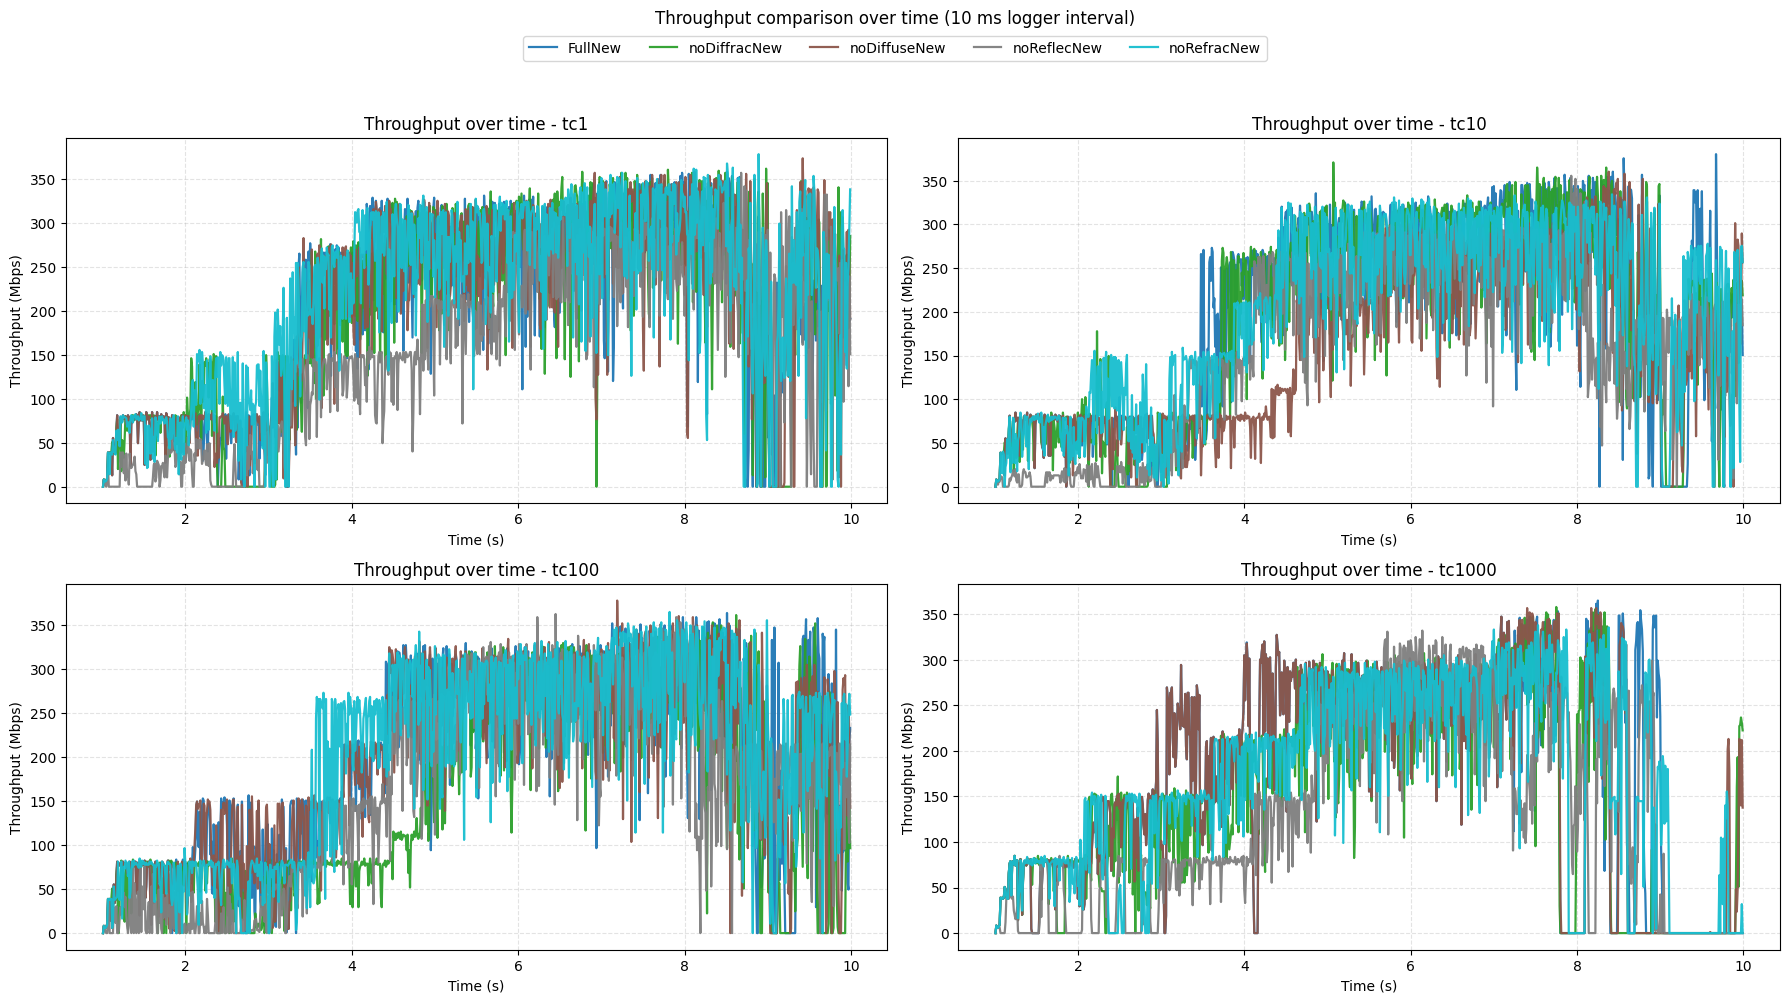

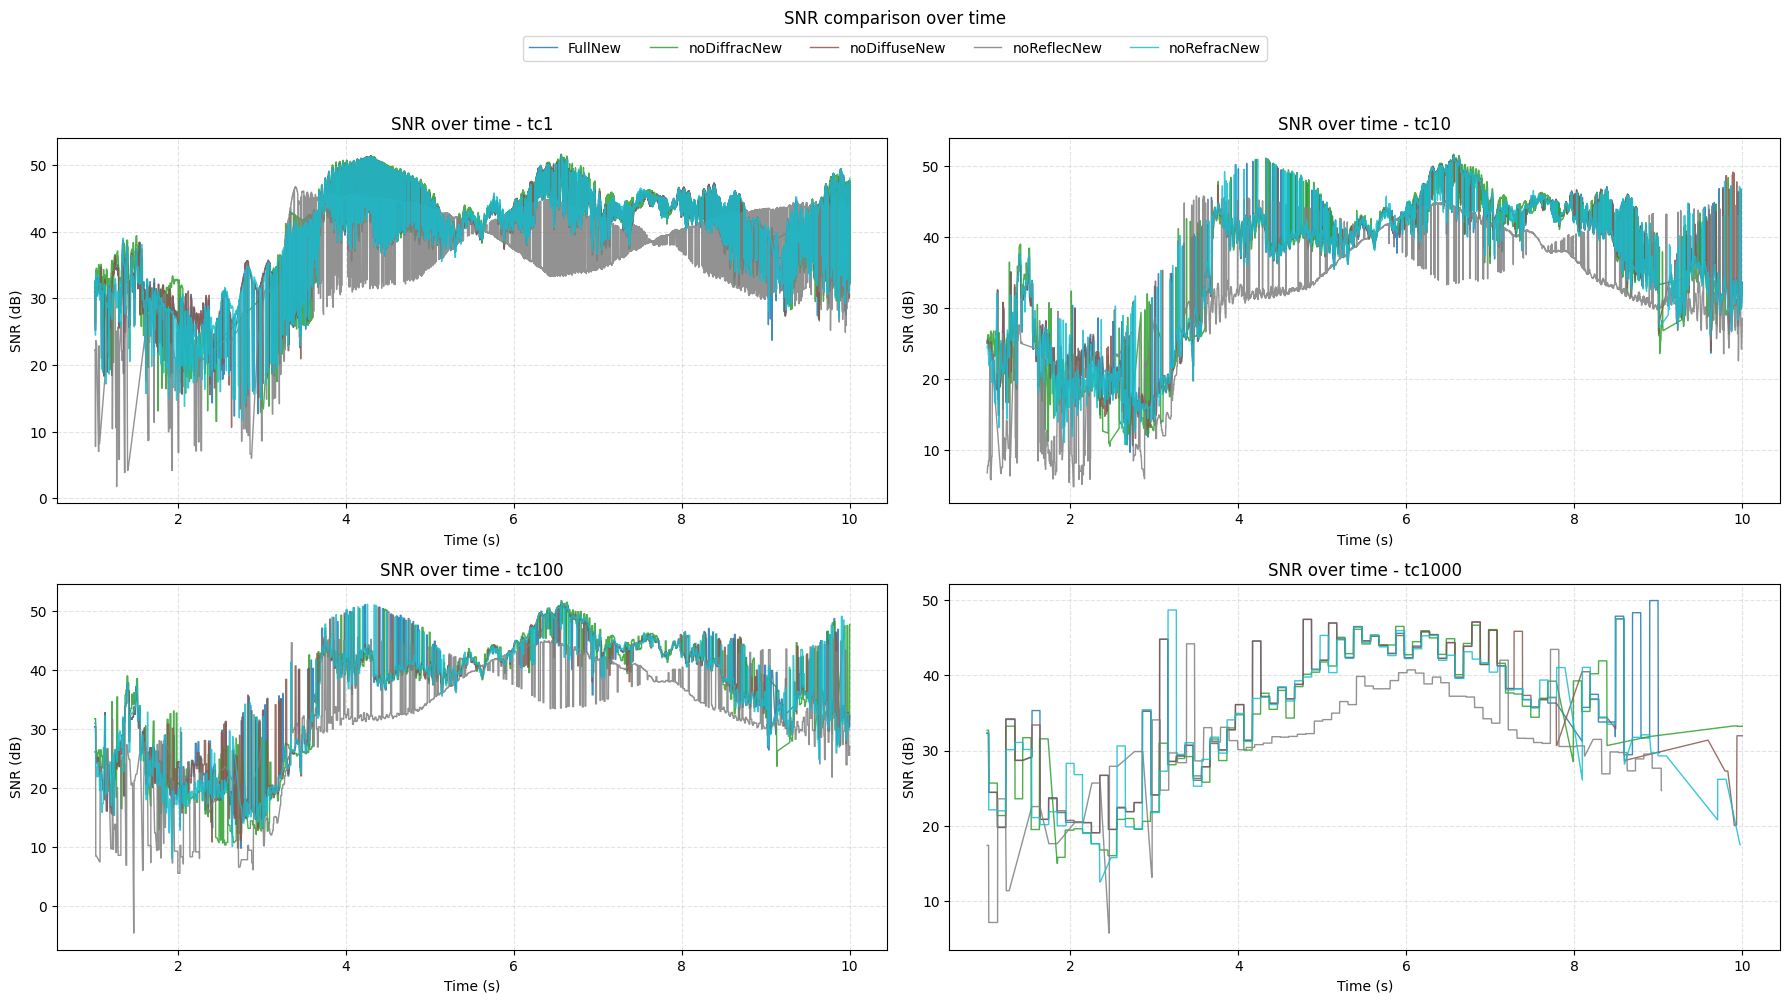

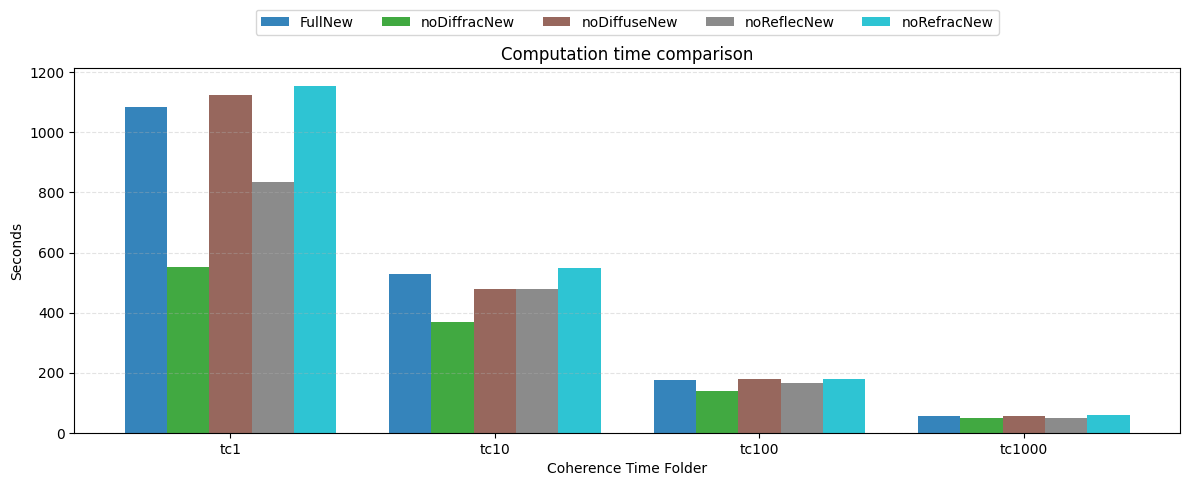

Error baseline: FullNew
SNR error uses 0.10s time bins.
Setting             TC      TP RMSE    TP RRMSE%     SNR RMSE    SNR RRMSE%
FullNew              1         0.00         0.00         0.00          0.00
noDiffracNew         1        73.02        35.42         1.91          4.80
noDiffuseNew         1        62.10        30.12         0.72          1.80
noReflecNew          1        92.49        44.86         6.60         16.63
noRefracNew          1        68.74        33.34         1.04          2.61
FullNew             10         0.00         0.00         0.00          0.00
noDiffracNew        10        66.67        34.34         1.72          4.79
noDiffuseNew        10        84.95        43.75         0.67          1.87
noReflecNew         10        87.20        44.91         6.02         16.79
noRefracNew         10        69.67        35.88         1.03          2.87
FullNew            100         0.00         0.00         0.00          0.00
noDiffracNew       100        95

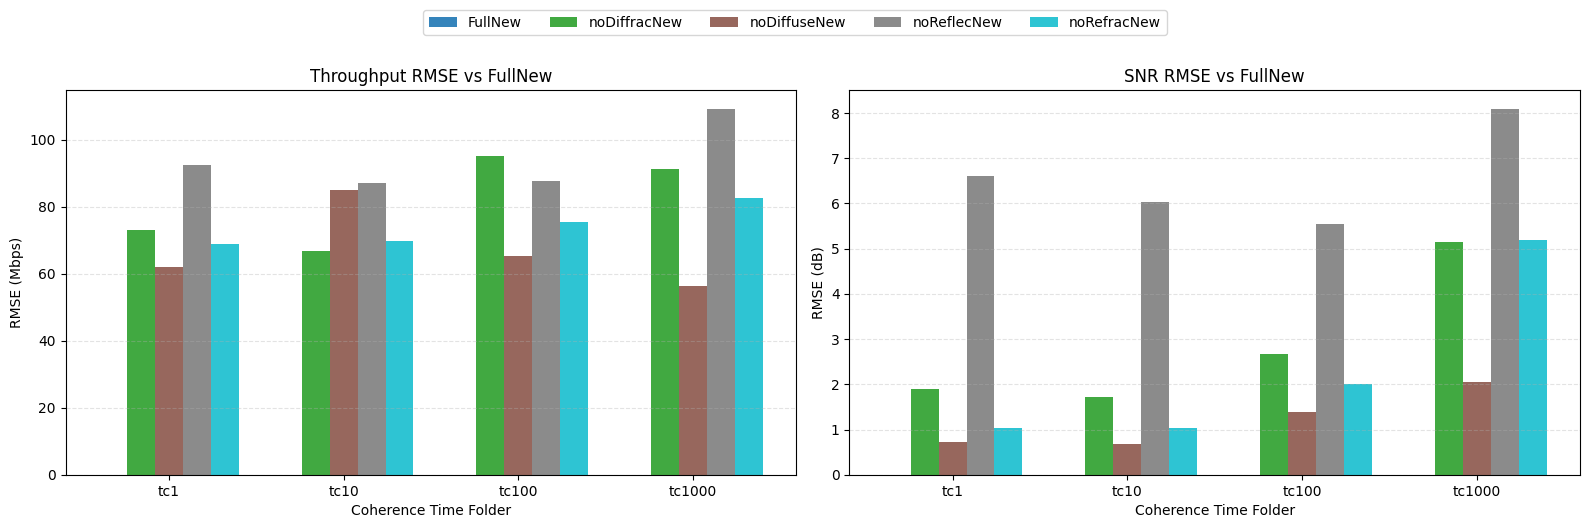

In [3]:
# Compare the new apartment result folders only. Each line plot compares the
# same coherence time across different propagation settings.
RESULT_SETS = {
    "FullNew": "./results_FullNew",
    "noDiffracNew": "./results_noDiffracNew",
    "noDiffuseNew": "./results_noDiffuseNew",
    "noReflecNew": "./results_noReflecNew",
    "noRefracNew": "./results_noRefracNew",
}

# Use FullNew as the baseline and measure how much each reduced setting deviates.
# RMSE is useful here because it stays in the original units and punishes bigger
# deviations more strongly than MAE. For SNR, packet timestamps do not line up
# perfectly, so the error is computed on time-binned SNR traces.
BASELINE_SETTING = "FullNew"
THROUGHPUT_INTERVAL_MS = 10
SNR_STA_NODE_ID = None  # Auto-detect from the logged STA node IDs.
SNR_ERROR_BIN_SECONDS = 0.1

coherence_times = sorted({tc for results_dir in RESULT_SETS.values() for tc in list_available_tcs(results_dir)})
if not coherence_times:
    raise FileNotFoundError("No matching *New result folders were found for comparison.")

plot_throughput_comparison(coherence_times, interval_ms=THROUGHPUT_INTERVAL_MS)
plot_snr_comparison(coherence_times, sta_node_id=SNR_STA_NODE_ID)
plot_computation_time_barplot(coherence_times)
error_rows = collect_error_rows(coherence_times)
print_error_summary(error_rows)
plot_error_barplots(error_rows, coherence_times)

In [ ]:
RESULT_SETS = {
    "FullNew": "./results_FullNew",
    "noDiffuseNew": "./results_noDiffuseNew",
}

coherence_times = sorted({tc for results_dir in RESULT_SETS.values() for tc in list_available_tcs(results_dir)})
if not coherence_times:
    raise FileNotFoundError("No matching *New result folders were found for comparison.")

plot_throughput_comparison(coherence_times, interval_ms=THROUGHPUT_INTERVAL_MS)
plot_snr_comparison(coherence_times, sta_node_id=SNR_STA_NODE_ID)
plot_computation_time_barplot(coherence_times)
error_rows = collect_error_rows(coherence_times)
print_error_summary(error_rows)
plot_error_barplots(error_rows, coherence_times)

In [ ]:
RESULT_SETS = {
    "FullNew": "./results_FullNew",
    "noRefracNew": "./results_noRefracNew",
}
coherence_times = sorted({tc for results_dir in RESULT_SETS.values() for tc in list_available_tcs(results_dir)})
if not coherence_times:
    raise FileNotFoundError("No matching *New result folders were found for comparison.")

plot_throughput_comparison(coherence_times, interval_ms=THROUGHPUT_INTERVAL_MS)
plot_snr_comparison(coherence_times, sta_node_id=SNR_STA_NODE_ID)
plot_computation_time_barplot(coherence_times)
error_rows = collect_error_rows(coherence_times)
print_error_summary(error_rows)
plot_error_barplots(error_rows, coherence_times)

In [ ]:
RESULT_SETS = {
    "FullNew": "./results_FullNew",
    "noReflecNew": "./results_noReflecNew",
}
coherence_times = sorted({tc for results_dir in RESULT_SETS.values() for tc in list_available_tcs(results_dir)})
if not coherence_times:
    raise FileNotFoundError("No matching *New result folders were found for comparison.")

plot_throughput_comparison(coherence_times, interval_ms=THROUGHPUT_INTERVAL_MS)
plot_snr_comparison(coherence_times, sta_node_id=SNR_STA_NODE_ID)
plot_computation_time_barplot(coherence_times)
error_rows = collect_error_rows(coherence_times)
print_error_summary(error_rows)
plot_error_barplots(error_rows, coherence_times)

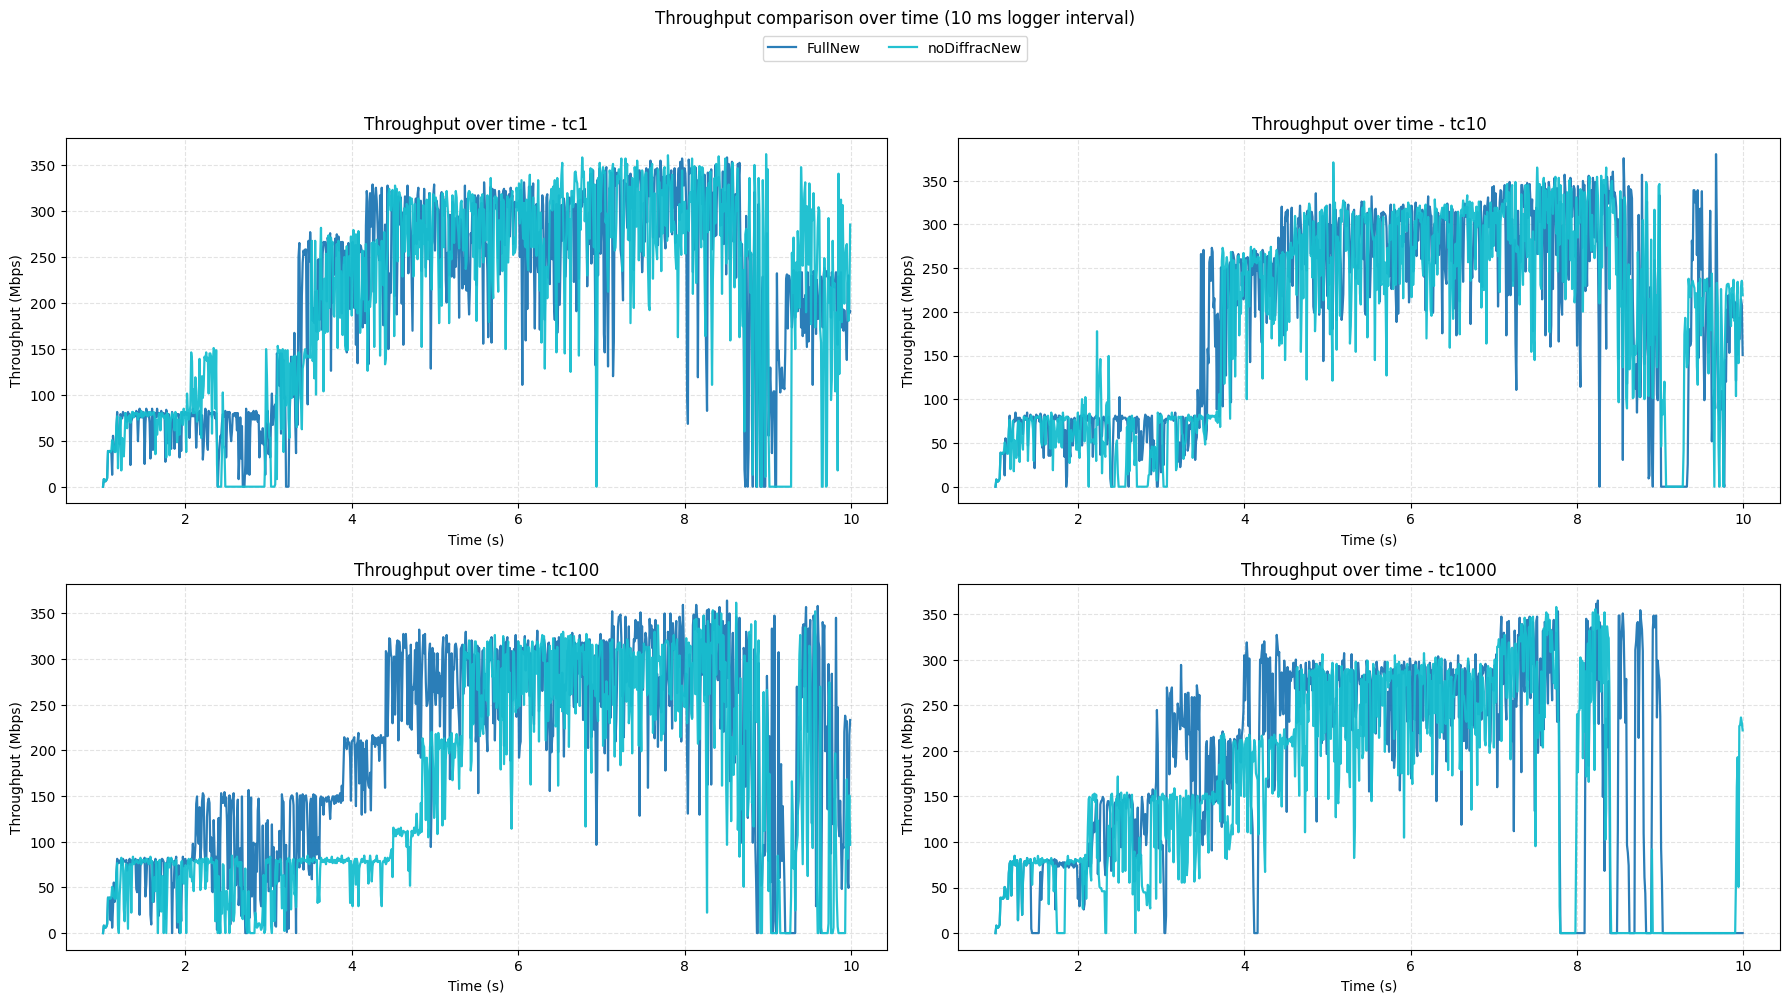

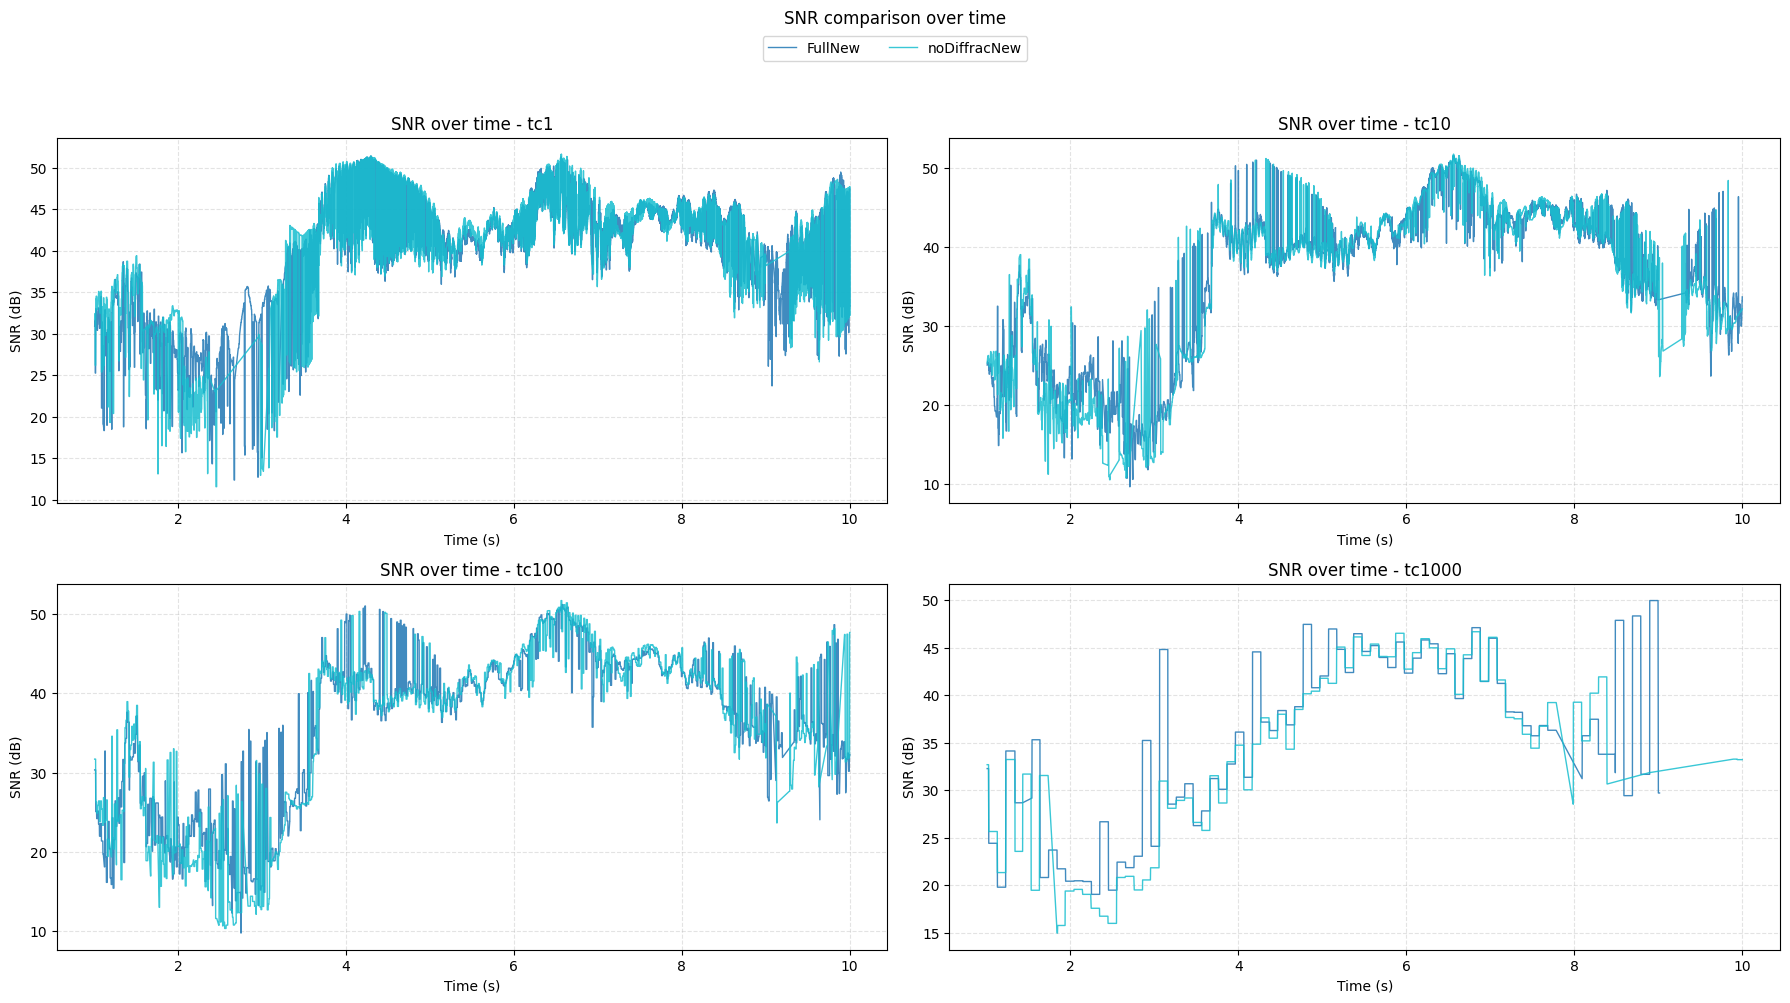

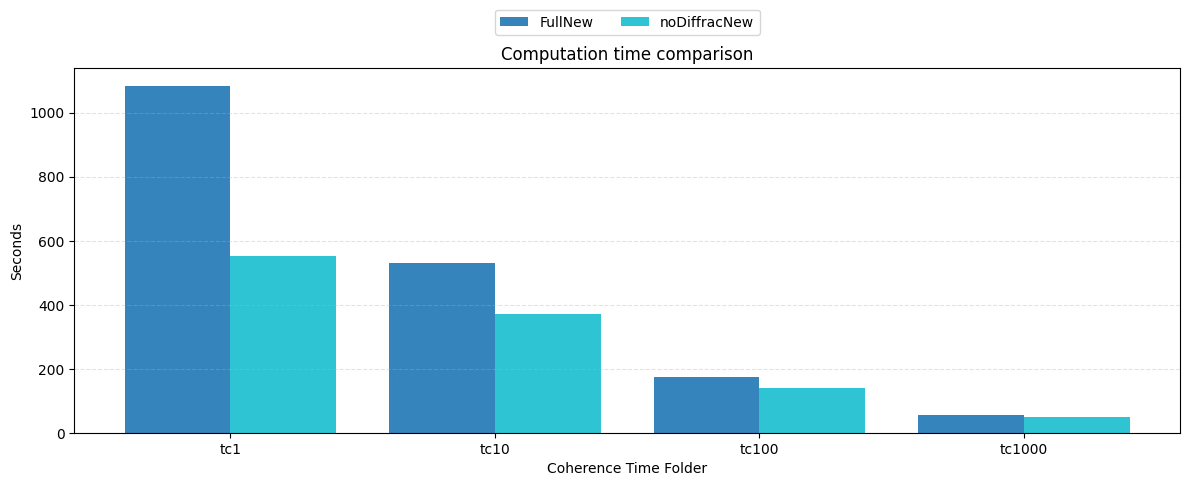

KeyboardInterrupt: 

In [4]:
RESULT_SETS = {
    "FullNew": "./results_FullNew",
    "noDiffracNew": "./results_noDiffracNew",
}
coherence_times = sorted({tc for results_dir in RESULT_SETS.values() for tc in list_available_tcs(results_dir)})
if not coherence_times:
    raise FileNotFoundError("No matching *New result folders were found for comparison.")

plot_throughput_comparison(coherence_times, interval_ms=THROUGHPUT_INTERVAL_MS)
plot_snr_comparison(coherence_times, sta_node_id=SNR_STA_NODE_ID)
plot_computation_time_barplot(coherence_times)
error_rows = collect_error_rows(coherence_times)
print_error_summary(error_rows)
plot_error_barplots(error_rows, coherence_times)

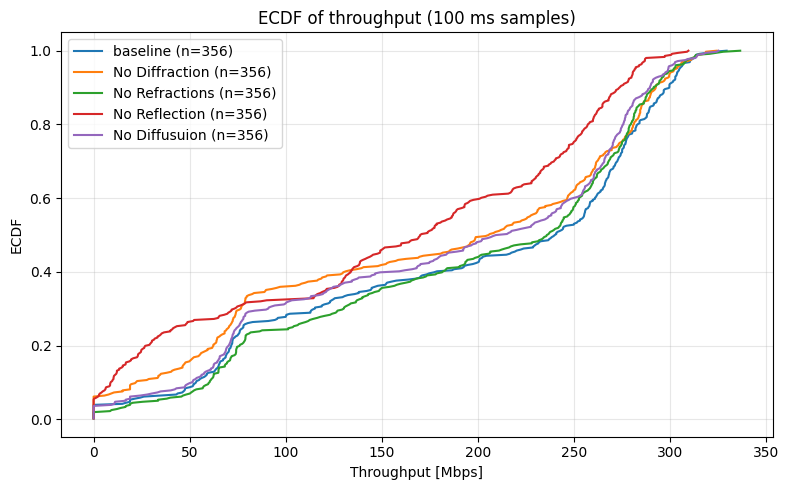

,label,num_files,num_samples,mean_Mbps,median_Mbps,p10_Mbps,p90_Mbps
1,No Diffraction,4,356,173.992066,205.8445,22.37440,292.5750
4,No Diffusuion,4,356,181.261745,212.2625,51.63775,289.5720
3,No Reflection,4,356,154.370138,170.3400,9.30304,273.7335
2,No Refractions,4,356,193.127725,236.3440,60.46975,291.5740
0,baseline,4,356,192.722518,240.4070,53.46305,299.5815


In [8]:
"""
#
# This Cell creates an ECDF Plot of the Throughput for all server settings (TODO: LoS results) with a measurement time of 100ms (change via interval_ms variable)
#
"""

import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

groups = {
    "baseline": "results_FullNew/tc*/throughput_results_*.csv",
    "No Diffraction": "results_noDiffracNew/tc*/throughput_results_*.csv",
    "No Refractions": "results_noRefracNew/tc*/throughput_results_*.csv",
    "No Reflection": "results_noReflecNew/tc*/throughput_results_*.csv",
    "No Diffusuion": "results_noDiffuseNew/tc*/throughput_results_*.csv",
}

# Use only one sampling interval from the CSVs: 10 or 100
interval_ms = 100

# Optional filters
drop_zero_throughput = False   # set True if you want to ignore exact 0 Mbps samples
time_min = None                # e.g. 2.0 to ignore startup phase
time_max = None                # e.g. 9.5 to ignore shutdown phase

# Plot settings
plt.figure(figsize=(8, 5))


def ecdf(values):
    """Return x, y for an ECDF."""
    x = np.sort(np.asarray(values))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


summary_rows = []

for label, pattern in groups.items():
    files = sorted(glob.glob(pattern))
    if not files:
        print(f"[warn] No files found for '{label}' with pattern: {pattern}")
        continue

    all_tp = []

    for file in files:
        df = pd.read_csv(file)

        # Normalize column names in case of whitespace
        df.columns = [c.strip() for c in df.columns]

        # Expected columns:
        # Time, Throughput_Mbps, measuring interval in ms
        df = df[df["measuring interval in ms"] == interval_ms]

        if time_min is not None:
            df = df[df["Time"] >= time_min]
        if time_max is not None:
            df = df[df["Time"] <= time_max]
        if drop_zero_throughput:
            df = df[df["Throughput_Mbps"] > 0]

        all_tp.extend(df["Throughput_Mbps"].dropna().to_numpy())

    if len(all_tp) == 0:
        print(f"[warn] No throughput samples left for '{label}' after filtering.")
        continue

    x, y = ecdf(all_tp)
    plt.plot(x, y, label=f"{label} (n={len(all_tp)})")

    summary_rows.append({
        "label": label,
        "num_files": len(files),
        "num_samples": len(all_tp),
        "mean_Mbps": np.mean(all_tp),
        "median_Mbps": np.median(all_tp),
        "p10_Mbps": np.percentile(all_tp, 10),
        "p90_Mbps": np.percentile(all_tp, 90),
    })

plt.xlabel("Throughput [Mbps]")
plt.ylabel("ECDF")
plt.title(f"ECDF of throughput ({interval_ms} ms samples)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Show a small numeric summary as well
summary_df = pd.DataFrame(summary_rows).sort_values("label")
summary_df